## Agent publisher

### Install libraries

In [1]:
# Install this notebook's direct dependencies.
%pip install -qU langgraph langgraph-supervisor langchain-tavily langchain-openai python-dotenv
# Google Colab: add OPENAI_API_KEY in the Secrets panel (🔑) and grant this notebook access.
# Uncomment these lines to load it from Colab Secrets into this runtime:
# from google.colab import userdata
# import os
# os.environ["OPENAI_API_KEY"] = userdata.get("OPENAI_API_KEY")
# Locally, put OPENAI_API_KEY=... in a .env file; do not commit the key.
# For Tavily search, also add TAVILY_API_KEY to Colab Secrets or your local .env file.
# from google.colab import userdata
# os.environ["TAVILY_API_KEY"] = userdata.get("TAVILY_API_KEY")

Note: you may need to restart the kernel to use updated packages.


In [2]:
from dotenv import load_dotenv
load_dotenv()

True

In [3]:
from langchain_tavily import TavilySearch

web_search = TavilySearch(max_results=3)
web_search_results = web_search.invoke("Who is the prime minister of Poland?")

print(web_search_results["results"][0]["content"])

Donald Franciszek Tusk (born 22 April 1957) is a Polish politician and historian who has served as the prime minister of Poland since 2023, previously holding the office from 2007 to 2014. Tusk was President of the European Council from 2014 to 2019 and led the European People's Party from 2019 to 2022. He co-founded the Civic Platform (PO), one of the dominant Polish political parties, and was its longtime leader – from 2003 to 2014 and again from 2021 to 2025 – before it merged into the Civic [...] | Tusk in 2025 |
| Prime Minister of Poland |
| Incumbent |
| Assumed office  13 December 2023 |
| President | Andrzej Duda Karol Nawrocki |
| Deputy | Władysław Kosiniak-Kamysz   Krzysztof Gawkowski   Radosław Sikorski |
| Preceded by | Mateusz Morawiecki |
| In office 16 November 2007 – 22 September 2014 |
| President | Lech Kaczyński Acting (2010)    Bronisław Komorowski  Bogdan Borusewicz  Grzegorz Schetyna Bronisław Komorowski | [...] Prime Minister of Poland (2007–2014; since 2023)



### Pretty printing helper functions

In [4]:
from langchain_core.messages import convert_to_messages


def pretty_print_message(message, indent=False):
    pretty_message = message.pretty_repr(html=True)
    if not indent:
        print(pretty_message)
        return

    indented = "\n".join("\t" + c for c in pretty_message.split("\n"))
    print(indented)


def pretty_print_messages(update, last_message=False):
    is_subgraph = False
    if isinstance(update, tuple):
        ns, update = update
        # skip parent graph updates in the printouts
        if len(ns) == 0:
            return

        graph_id = ns[-1].split(":")[0]
        print(f"Update from subgraph {graph_id}:")
        print("\n")
        is_subgraph = True

    for node_name, node_update in update.items():
        update_label = f"Update from node {node_name}:"
        if is_subgraph:
            update_label = "\t" + update_label

        print(update_label)
        print("\n")

        messages = convert_to_messages(node_update["messages"])
        if last_message:
            messages = messages[-1:]

        for m in messages:
            pretty_print_message(m, indent=is_subgraph)
        print("\n")


def _name_and_content(msg):
    if isinstance(msg, dict):
        return msg.get("name", msg.get("role", "user")), msg.get("content", str(msg))
    if isinstance(msg, BaseMessage):
        name = getattr(msg, "name", None) or getattr(msg, "type", "user")
        return name, msg.content
    return "user", str(msg)


### Agent researcher

In [5]:
from langchain_core.output_parsers import StrOutputParser
from langchain_openai import ChatOpenAI
from langchain_core.prompts import ChatPromptTemplate

def research_agent_node(state):
    messages = state["messages"]
    user_request = messages[0].content  # BaseMessage OK

    search_results = web_search.invoke(user_request)
    research_content = []
    for result in search_results["results"][:3]:
        research_content.append(f"Source: {result['url']}\nContent: {result['content']}\n")
    research_text = "\n---\n".join(research_content)

    research_prompt = ChatPromptTemplate.from_messages([
("system", """You're the Researcher. You have access to fragments from the 'search engine' (RESEARCH).
Your goal is to provide factual, concise facts and data supporting the topic.
Refer to the fragments and do not invent. Write concretely and briefly.
After you finish your task, respond directly to the moderator.
Reply using only the results of your work, do not include the text."""),
("user", "Topic: {topic}\n\nSearch results:\n{research_data}")

    ])

    model = ChatOpenAI(model="gpt-6.1-sol")
    chain = research_prompt | model | StrOutputParser()
    response = chain.invoke({"topic": user_request, "research_data": research_text})

    return {"messages": [{"role": "assistant", "content": response, "name": "research_agent"}]}


### Agent author

In [6]:
from langchain_core.messages import BaseMessage

def _name_and_content(msg):
    if isinstance(msg, dict):
        return msg.get("name", msg.get("role", "user")), msg.get("content", str(msg))
    if isinstance(msg, BaseMessage):
        name = getattr(msg, "name", None) or getattr(msg, "type", "user")
        return name, msg.content
    # fallback
    return "user", str(msg)


In [7]:
def author_agent_node(state):
    messages = state["messages"]
    has_critic_already_intervened = state.get("critic_marked", False)

    if has_critic_already_intervened:
        author_prompt = ChatPromptTemplate.from_messages([
("system", """You're the Expert-Editor. You have already received feedback from the Critic and you must improve your text.
Analyze the critic's comments and provide a revised version of the article that addresses their concerns.
Include all suggestions and fill in the indicated gaps. Write concretely.
After you finish your task, respond directly to the moderator.
Reply using only the results of your work, do not include the text."""),
("user", "Conversation history:\n{conversation_history}\n\nRevise the article taking into account the critic's feedback.")

        ])
    else:
        author_prompt = ChatPromptTemplate.from_messages([
("system", """You're the Expert. From the available facts, propose a practical solution/plan.
Include steps, requirements, and a minimal set of decisions. Write concretely.
After you finish your task, respond directly to the moderator.
Reply using only the results of your work, do not include the text."""),
("user", "Based on the research, create an article:\n{conversation_history}")

        ])

    conversation_history = "\n".join(
        f"{_name_and_content(m)[0]}: {_name_and_content(m)[1]}"
        for m in messages
    )

    model = ChatOpenAI(model="gpt-6.1-sol")
    chain = author_prompt | model | StrOutputParser()
    response = chain.invoke({"conversation_history": conversation_history})

    return {"messages": [{"role": "assistant", "content": response, "name": "author_agent"}]}


### Agent critic

In [8]:
def critic_agent_node(state):
    messages = state["messages"]

    conversation_history = "\n".join(
        f"{_name_and_content(m)[0]}: {_name_and_content(m)[1]}"
        for m in messages
    )

    critic_prompt = ChatPromptTemplate.from_messages([
("system", """You're the Critic. Your role is to find gaps, risks, and ambiguities in the proposal.
Ask probing questions and point out missing elements. Be constructive.
After analyzing the author's work, if you see significant gaps or problems, end your response with the words: "needs improvement"
If the work is satisfactory and does not require significant corrections, end with the words: "approved"
After you finish your task, respond directly to the moderator.
Reply using only the results of your work, do not include the text."""),
("user", "Analyze the author's work:\n{conversation_history}")
    ])

    model = ChatOpenAI(model="gpt-6.1-sol")
    chain = critic_prompt | model | StrOutputParser()
    response = chain.invoke({"conversation_history": conversation_history})

    updates = {
        "messages": [{"role": "assistant", "content": response, "name": "critic_agent"}]
    }
    if not state.get("critic_marked", False):
        updates["critic_marked"] = True

    return updates


def should_continue(state):
    last = state["messages"][-1]
    _, content = _name_and_content(last)
    content = content.lower()
    return "author_agent" if "needs improvement" in content else "end"

### Build graph

In [9]:
from typing import TypedDict, Annotated
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages

class WorkflowState(TypedDict):
    messages: Annotated[list, add_messages]
    critic_marked: bool

supervisor = (
    StateGraph(WorkflowState)
    .add_node("research_agent", research_agent_node)
    .add_node("author_agent", author_agent_node)
    .add_node("critic_agent", critic_agent_node)
    .add_edge(START, "research_agent")
    .add_edge("research_agent", "author_agent")
    .add_edge("author_agent", "critic_agent")
    .add_conditional_edges("critic_agent", should_continue, {
        "author_agent": "author_agent",
        "end": END
    })
    .compile(debug=True)
)


### Display graph

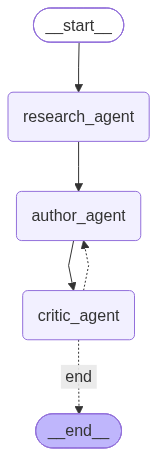

In [10]:
from IPython.display import display, Image

display(Image(supervisor.get_graph().draw_mermaid_png()))

### Run graph and generate the article

In [11]:
for chunk in supervisor.stream(
    {
        "messages": [{
            "role": "user",
            "content": "Generate an article on the topic: How to build a 'Publisher' agent application based on the LangGraph library",
        }],
        "critic_marked": False,
    },
    subgraphs=True,
):
    pretty_print_messages(chunk, last_message=True)


[values] {'messages': [HumanMessage(content="Generate an article on the topic: How to build a 'Publisher' agent application based on the LangGraph library", additional_kwargs={}, response_metadata={}, id='d9d3db90-3f17-430d-8187-64f3166e2708')], 'critic_marked': False}
[updates] {'research_agent': {'messages': [{'role': 'assistant', 'content': '## Building a “Publisher” Agent with LangGraph: Research Findings\n\n### Verified foundations\n\n- **State is the starting point.** A LangGraph application defines shared state using a typed dictionary or Pydantic model. Nodes read that state and return updates. Reducers determine how updates merge, which matters especially for accumulating message histories. [1]\n- **Nodes implement individual operations.** Each node receives the current state, performs computation, and returns a partial state update. Common roles include LLM reasoning, tool execution, and final-output formatting. [1]\n- **Conditional edges enable agent loops.** Routing can dep